# 01 — Project Overview and Setup

This notebook is the entry point for the **Fe-porphyrin electronic coupling ML model**
project. It introduces the system, the dataset, and the recommended workflow.

## What this project does

We predict the electronic coupling $J$ for hole transport between two stacked
Fe-porphyrin units, given only their atomic coordinates. The reference $J$ values
come from constrained DFT-CI (CDFT-CI) at the SRSH-PCM level — accurate but
expensive (~30 min per dimer). The model produces $J$ in milliseconds from
geometry alone.

## The recommended model

`v4_srsh_aug` — a Random Forest on:

- **11 symmetry-adapted geometric features** (interplanar distance, lateral slip,
  twist, tilt, all expressed in a $D_{4h}$-equivariant form)
- **3 monomer-orbital overlap features** ($S_{12}$, $S_{12}^2$, $\log|S_{12}|$)
  computed from the SRSH-PCM cation $\alpha$-SOMO of Fe-porphine

Trained on **815 structures** (704 systematic + 111 MD-sampled).

## Results headline

| Set | log MAE | Pearson $r$ |
|---|---|---|
| Held-out test (120) | **0.27** | 0.83 |
| MD validation (13 conformations) | 0.83 | 0.36 |

## Notebook map

| Notebook | What it shows |
|---|---|
| `01_overview.ipynb` | (this) project setup, dataset summary |
| `02_features_from_xyz.ipynb` | xyz dimer → 11-D symmetry-adapted feature vector |
| `03_homo_and_overlap.ipynb` | parse Q-Chem .fchk → HOMO → rotation-aware $S_{12}$ |
| `04_training_data.ipynb` | how the master CSV was built from raw outputs |
| `05_train_and_predict.ipynb` | train v4_srsh_aug, predict on a new dimer |
| `06_md_validation.ipynb` | validate predictions against $\Gamma^*$ for 15 MD conformations |
| `07_negative_results.ipynb` | what was tried and why it didn't help (EHT, ZINDO, DFTB+, HF) |

Read them in order; each notebook is self-contained but builds on the previous.


## Setup check

This cell verifies that all required packages are importable. If any fail, see
`requirements.txt` in the repo root.

In [1]:
import sys
print(f'Python: {sys.version.split()[0]}')

import numpy as np; print(f'numpy: {np.__version__}')
import pandas as pd; print(f'pandas: {pd.__version__}')
import sklearn; print(f'sklearn: {sklearn.__version__}')
import joblib; print(f'joblib: {joblib.__version__}')
import scipy; print(f'scipy: {scipy.__version__}')
import ase; print(f'ase: {ase.__version__}')

# pyscf and cclib are optional (only needed for notebooks 03 and 07)
try:
    import pyscf; print(f'pyscf: {pyscf.__version__}  (needed for notebook 03)')
except ImportError:
    print('pyscf: NOT INSTALLED  (notebook 03 will not run)')
try:
    import cclib; print(f'cclib: {cclib.__version__}  (needed for notebook 03)')
except ImportError:
    print('cclib: NOT INSTALLED  (notebook 03 will not run)')


Python: 3.8.17


numpy: 1.24.3
pandas: 2.0.3
sklearn: 1.3.0
joblib: 1.4.2
scipy: 1.10.1
ase: 3.23.0
pyscf: 2.5.0  (needed for notebook 03)
cclib: 1.8.1  (needed for notebook 03)


## Dataset summary

The master dataset is `data/master_dataset.csv` — one row per dimer structure,
with all features and labels precomputed.

In [2]:
import pandas as pd
df = pd.read_csv('../data/master_dataset.csv')
print(f'Total structures: {len(df)}')
print(f'Columns: {list(df.columns)}')
print()
print('By dataset:')
print(df['dataset'].value_counts())
print()
print('By split:')
print(df.groupby(['dataset', 'split']).size())


Total structures: 830
Columns: ['name', 'dataset', 'split', 'J_cdft_eV', 'log10_J_cdft', 'dz', 'dx', 'dy', 'cos_theta', 'cos_4phi', 'sin_4phi', 'cos_4psi', 'sin_4psi', 'd_lateral', 'cos_4alpha', 'sin_4alpha', 'S12_b3lyp', 'S12_srsh_singlet', 'S12_srsh_cation', 'S12_qchem_truth', 'J_eht_eV', 'J_zindo_eV', 'J_dftb_eV']

By dataset:
dataset
704_systematic    704
slater_111_md     111
md_validation      15
Name: count, dtype: int64

By split:
dataset         split     
704_systematic  test          141
                train         563
md_validation   validation     15
slater_111_md   test           23
                train          88
dtype: int64


## Quick coupling distribution

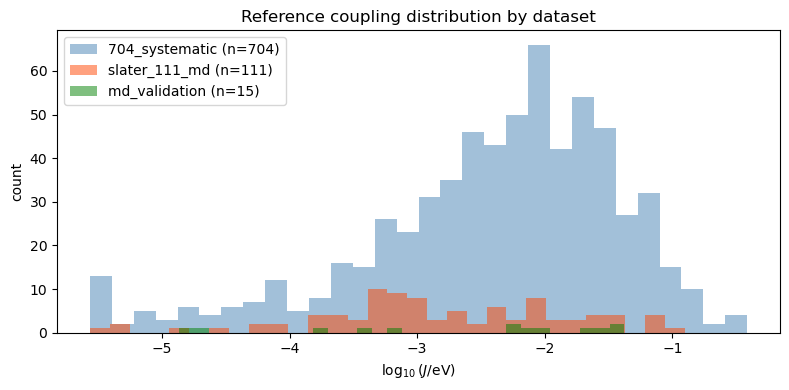

In [3]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
for dset, color in [('704_systematic', 'steelblue'),
                    ('slater_111_md', 'orangered'),
                    ('md_validation', 'green')]:
    sub = df[df['dataset'] == dset]
    j_pos = sub['J_cdft_eV'][sub['J_cdft_eV'] > 0]
    ax.hist(np.log10(j_pos), bins=30, alpha=0.5, label=f'{dset} (n={len(sub)})', color=color)
ax.set_xlabel('$\\log_{10}(J / \\mathrm{eV})$')
ax.set_ylabel('count')
ax.set_title('Reference coupling distribution by dataset')
ax.legend()
plt.tight_layout()
plt.show()


## Quick look at the symmetry-adapted features

The 11-dimensional feature vector encodes the relative position and orientation of
two porphyrin rings in a way that is invariant under the $D_{4h}$ symmetry of the
isolated porphyrin (a 4-fold rotation about the porphyrin normal must give the
same coupling). Notebook 02 explains how each feature is constructed.

In [4]:
feature_cols = ['dz', 'dx', 'dy', 'cos_theta',
                'cos_4phi', 'sin_4phi', 'cos_4psi', 'sin_4psi',
                'd_lateral', 'cos_4alpha', 'sin_4alpha']

# Show feature ranges for the systematic 704 set
sys_df = df[df['dataset'] == '704_systematic'][feature_cols]
print(sys_df.describe().round(3).T[['mean', 'std', 'min', 'max']])


             mean    std    min     max
dz          4.654  2.032  0.000   9.936
dx          4.067  2.817 -0.004  10.215
dy          1.949  2.628 -6.870   9.998
cos_theta   0.727  0.415 -0.966   1.000
cos_4phi    0.535  0.701 -1.000   1.000
sin_4phi   -0.005  0.472 -1.000   1.000
cos_4psi    0.583  0.666 -0.997   1.000
sin_4psi    0.044  0.463 -0.902   0.976
d_lateral   5.160  2.924  0.000  10.217
cos_4alpha -0.061  0.900 -0.997   1.000
sin_4alpha  0.116  0.416 -1.000   1.000


## Where to go next

- If you have a new dimer xyz file and want to predict $J$: jump to
  `05_train_and_predict.ipynb`, last cell.
- If you want to understand how the geometric features work: `02_features_from_xyz.ipynb`.
- If you want to reproduce the model from scratch: `04_training_data.ipynb`
  → `05_train_and_predict.ipynb`.
- If you want to know which alternative methods were tried and why they failed:
  `07_negative_results.ipynb`.

## Citation

If you use this code or model, please cite the report
(`report.pdf`, available on Overleaf).

## Code repository

Full code, data, models: https://github.com/mdbaer/porphyrin-coupling-ml
